# Knee osteoarthritis: binary classification with classical ML

This notebook is a **viewer** for the `kneeclf` package (`src/kneeclf/`). Training runs from the command line
(locally with `configs/quick.json`, on a server with `configs/full.json`) and writes everything to a run directory:
`metrics.json`, `comparison.csv`/`.md`, `params.json`, `model.pkl`, `train.log` and `figures/`.

- **Task**: Kellgren-Lawrence (KL) grades 0-4 are mapped to a binary label. Default `kl01_vs_2to4`: KL 0-1 = no OA,
  KL 2-4 = OA (the usual radiographic definition). The previous approach (`kl0_vs_1to4`) is still available,
  see [ADR-0002](../docs/adr/0002-binary-label-scheme.md).
- **Features and models**: raw pixels + PCA, and a numpy HOG descriptor, fed to logistic regression, RBF SVM,
  random forest and gradient boosting, each tuned by `GridSearchCV` (stratified folds, ROC-AUC).
- **Recall first**: the decision threshold is chosen on validation to reach a target sensitivity (default 0.85);
  the test set is used once, at the end, with everything frozen. See [ADR-0003](../docs/adr/0003-classical-features-and-recall-first-evaluation.md).

## Parameters

In [1]:
from pathlib import Path

# Works from the notebook folder (supervised_learning/) or from the repository root.
REPO = Path.cwd() if (Path.cwd() / "src" / "kneeclf").exists() else Path.cwd().parent
DATA_ROOT = REPO / "supervised_learning" / "Dataset_Knee_Osteoarthritis"  # not in the repo
RUNS = REPO / "runs"                     # parent of local run directories (git-ignored)
RUN_DIR = REPO / "results" / "supervised"  # versioned full run; None = latest run in RUNS
LAUNCH_QUICK = False                     # True = train with configs/quick.json first (needs DATA_ROOT)

## Optional: launch the quick configuration

Small sample (150 images per class), 64 px, tiny grids. Only a smoke test: its numbers are not results.

In [2]:
import subprocess, sys, os

if LAUNCH_QUICK and DATA_ROOT.exists():
    env = {**os.environ, "PYTHONPATH": str(REPO / "src")}
    cmd = [sys.executable, "-m", "kneeclf", "--data", str(DATA_ROOT),
           "--config", str(REPO / "configs" / "quick.json"), "--output", str(RUNS)]
    print(" ".join(cmd))
    subprocess.run(cmd, env=env, check=True)
    RUN_DIR = None  # show the run just produced
else:
    print("quick training skipped (LAUNCH_QUICK is False or the dataset is missing): showing", RUN_DIR.relative_to(REPO))

quick training skipped (LAUNCH_QUICK is False or the dataset is missing): showing results/supervised


## Load a run

In [3]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display

if RUN_DIR is None:
    runs = sorted(p for p in RUNS.glob("*") if (p / "metrics.json").exists())
    assert runs, f"no finished run under {RUNS.resolve()}"
    RUN_DIR = runs[-1]
metrics = json.loads((RUN_DIR / "metrics.json").read_text())
print("run:", RUN_DIR.relative_to(REPO))
print("label scheme:", metrics["config"]["label_scheme"], "| image size:", metrics["config"]["image_size"])
print("environment:", metrics["environment"])

run: results/supervised
label scheme: kl01_vs_2to4 | image size: 112
environment: {'python': '3.12.3', 'platform': 'Linux-6.8.0-147-generic-x86_64-with-glibc2.39', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'pandas': '3.1.1', 'matplotlib': '3.11.2', 'pillow': '13.0.0'}


### Data profile

Train is balanced by undersampling (if `balance_train`); validation and test keep their real class ratio.

In [4]:
pd.DataFrame({s: {"files": p["files_found"], "kept": p["kept"], **{f"label {k}": v for k, v in p["labels_kept"].items()},
                  "MB": p["memory_mb"]} for s, p in metrics["data_profile"].items()}).T

,files,kept,label 0,label 1,MB
train,5778.0,4892.0,2446.0,2446.0,234.1
val,826.0,826.0,481.0,345.0,39.5
test,1656.0,1656.0,935.0,721.0,79.2


### Candidate comparison (validation)

Each candidate gets its own threshold tuned on validation; the ranking uses validation ROC-AUC, which does not depend on the threshold.

In [5]:
comparison = pd.read_csv(RUN_DIR / "comparison.csv")
comparison

,candidate,features,cv_roc_auc,val_roc_auc,val_pr_auc,val_recall,val_specificity,val_f2,val_balanced_accuracy,search_seconds,best_params
0,hog_svc,hog,0.8614,0.8607,0.8369,0.8522,0.6736,0.8028,0.7629,622.89,"{""svc__C"": 10, ""svc__gamma"": ""scale""}"
1,hog_logreg,hog,0.8544,0.8566,0.8360,0.8522,0.6445,0.7967,0.7483,19.47,"{""logreg__C"": 0.0003}"
2,hog_rf,hog,0.8217,0.8379,0.8024,0.8522,0.6341,0.7946,0.7431,409.32,"{""rf__max_depth"": 20, ""rf__min_samples_leaf"": ..."
3,hog_pca_hgb,hog,0.8018,0.8093,0.7790,0.8522,0.5343,0.7745,0.6932,759.41,"{""hgb__learning_rate"": 0.1, ""hgb__max_leaf_nod..."
4,raw_pca_svc,raw,0.7800,0.7924,0.7382,0.8522,0.5509,0.7778,0.7016,70.06,"{""pca__n_components"": 200, ""svc__C"": 10, ""svc_..."
5,raw_pca_logreg,raw,0.7856,0.7788,0.7460,0.8522,0.4823,0.7644,0.6673,132.06,"{""logreg__C"": 0.01, ""pca__n_components"": 200}"


### Selected model

In [6]:
sel = metrics["selected"]
print(f"{sel['candidate']}  params={sel['best_params']}  threshold={sel['threshold']:.4f} ({sel['threshold_mode']}, target recall {sel['target_recall']})")
pd.DataFrame({"validation": metrics["validation"], "test": metrics["test"]}).drop(["confusion_matrix"])

hog_svc  params={'svc__C': 10, 'svc__gamma': 'scale'}  threshold=-0.2003 (target_recall, target recall 0.85)


,validation,test
n,826,1656
threshold,-0.2003,-0.2003
accuracy,0.7482,0.7566
balanced_accuracy,0.7629,0.7651
precision,0.6519,0.6807
recall,0.8522,0.8308
specificity,0.6736,0.6995
f1,0.7387,0.7483
f2,0.8028,0.7957
roc_auc,0.8607,0.8612


### Test set (touched once)

Recall = sensitivity (OA cases found); specificity = healthy knees correctly cleared.

**test_curves.png**

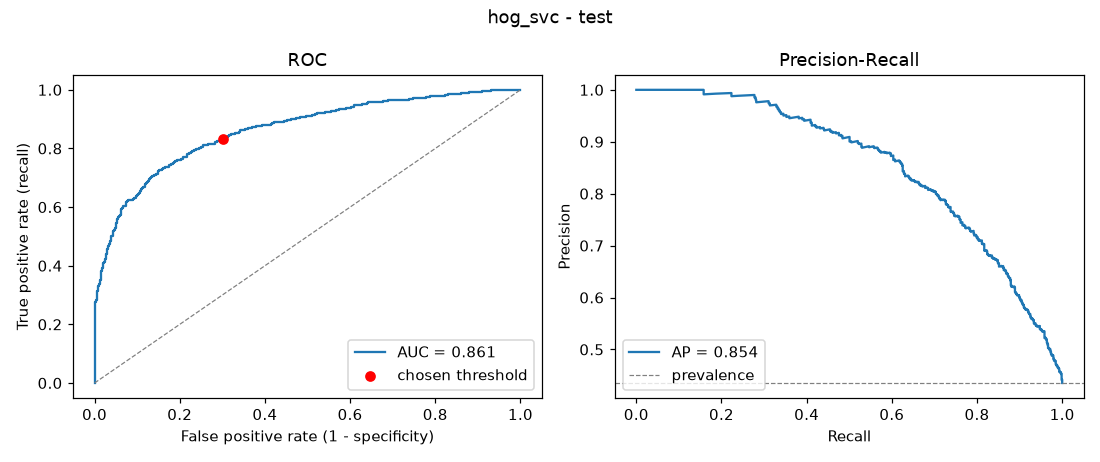

**test_confusion.png**

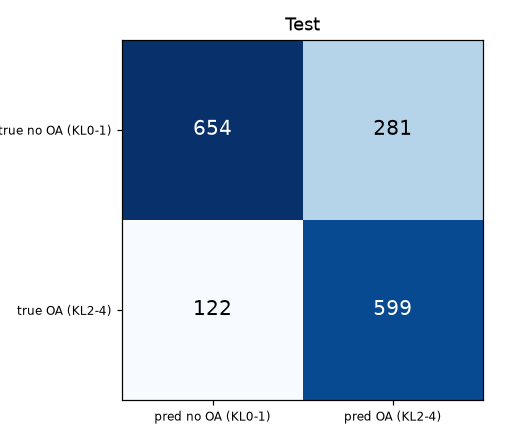

**val_curves.png**

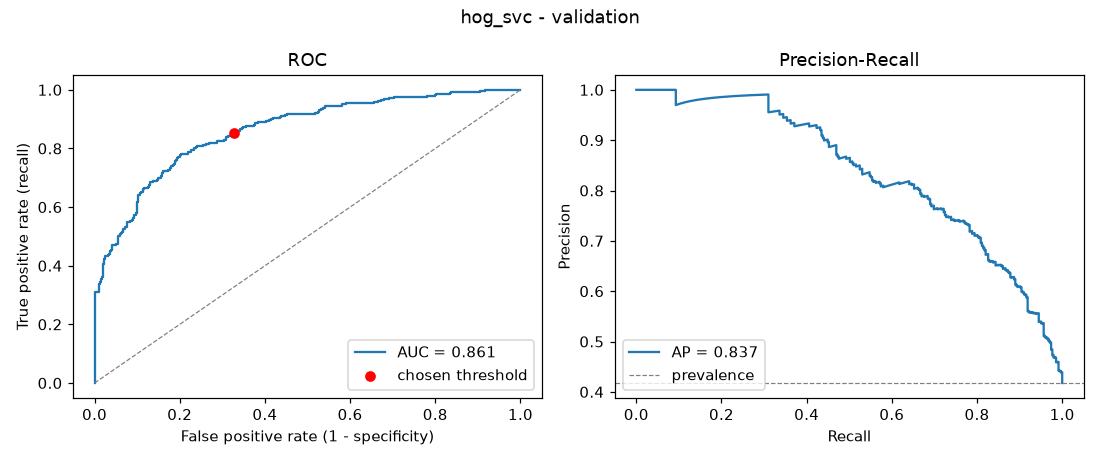

**val_confusion.png**

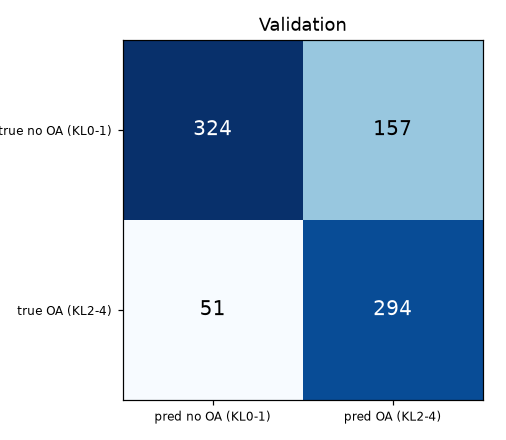

In [7]:
for f in ["test_curves.png", "test_confusion.png", "val_curves.png", "val_confusion.png"]:
    p = RUN_DIR / "figures" / f
    if p.exists():
        display(Markdown(f"**{f}**"), Image(filename=str(p)))

### Timings

In [8]:
pd.Series(metrics["timings"], name="seconds").to_frame()

,seconds
load_seconds,32.9500
features_hog_seconds,33.3000
features_raw_seconds,2.5700
test_predict_seconds,48.7492
total_seconds,2187.9600


## Reading the results

- A high recall with a low specificity means the threshold buys sensitivity with false alarms: compare the
  confusion matrices of validation and test to check the threshold transferred.
- KL 1 ("doubtful") is radiographically close to both KL 0 and KL 2: most errors are expected at that border.
- These models see global texture and edges, not the joint space width a radiologist measures; they are
  baselines, not a diagnostic tool.